# Metrics by Division Level (J&J only)

Compare divergence metrics across the six main J&J division levels.
One bar chart per metric; bars show the mean across all scoresheets in that category,
with error bars giving the 95% confidence interval of the mean (±1.96·sd/√n).
Levels: Newcomer, Novice, Intermediate, Advanced, All-Star, Champions.

In [1]:
from pathlib import Path
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

project_root = Path(".").resolve().parent

df_raw = pd.read_csv(project_root / "data" / "metrics.csv")
print(f"Total rows: {len(df_raw)}")

Total rows: 1459


In [2]:
LEVEL_LABELS = {
    "Newcomer":     "new",
    "Novice":       "nov",
    "Intermediate": "int",
    "Advanced":     "adv",
    "All-Star":     "als",
    "Champions":    "chp",
}
LEVEL_ORDER = list(LEVEL_LABELS.values())  # new → chp

df = df_raw[
    (df_raw["dance_format"] == "Jack & Jill") &
    (df_raw["division_level"].isin(LEVEL_LABELS))
].copy()

df["level"] = df["division_level"].map(LEVEL_LABELS)

print(f"Rows after filter: {len(df)}")
print(df["level"].value_counts().reindex(LEVEL_ORDER))

Rows after filter: 710
level
new    126
nov    146
int    143
adv    131
als    121
chp     43
Name: count, dtype: int64


In [3]:
METRICS = [
    # higher = more agreement
    ("kendall_w",               "Kendall's W",                     "higher = more agreement"),
    ("mean_pairwise_rho",       "Mean pairwise Spearman ρ",        "higher = more agreement"),
    ("mean_pairwise_tau",       "Mean pairwise Kendall τ",         "higher = more agreement"),
    ("overlap_at_3",            "Mean overlap @ 3",                "higher = more agreement"),
    ("overlap_at_5",            "Mean overlap @ 5",                "higher = more agreement"),
    ("jaccard_at_3",            "Mean Jaccard @ 3",                "higher = more agreement"),
    ("jaccard_at_5",            "Mean Jaccard @ 5",                "higher = more agreement"),
    # ("min_pairwise_tau",        "Min pairwise τ",                  "higher = more agreement"),
    # ("min_pairwise_rho",        "Min pairwise ρ",                  "higher = more agreement"),

    # lower = more agreement
    ("tau_distance",            "Kendall τ distance",              "lower = more agreement"),
    ("footrule_mean",           "Mean Spearman footrule",          "lower = more agreement"),
    ("mean_abs_rank_dev_mean",  "Mean abs rank deviation (mean)",  "lower = more agreement"),
    ("mean_abs_rank_dev_median","Mean abs rank deviation (median)","lower = more agreement"),
    ("sd_rank",                 "SD of ranks",                     "lower = more agreement"),
    # ("sd_pairwise_tau",         "SD of pairwise τ",                "lower = more consistent"),
    # ("sd_pairwise_rho",         "SD of pairwise ρ",                "lower = more consistent"),
]

metric_cols = [col for col, _, _ in METRICS]
agg_mean = df.groupby("level")[metric_cols].mean().reindex(LEVEL_ORDER).reset_index()
# 95% CI half-width of the mean: 1.96 · sem, where sem() = sd/√n
agg_ci = df.groupby("level")[metric_cols].sem().reindex(LEVEL_ORDER).reset_index()
agg_ci[metric_cols] *= 1.96

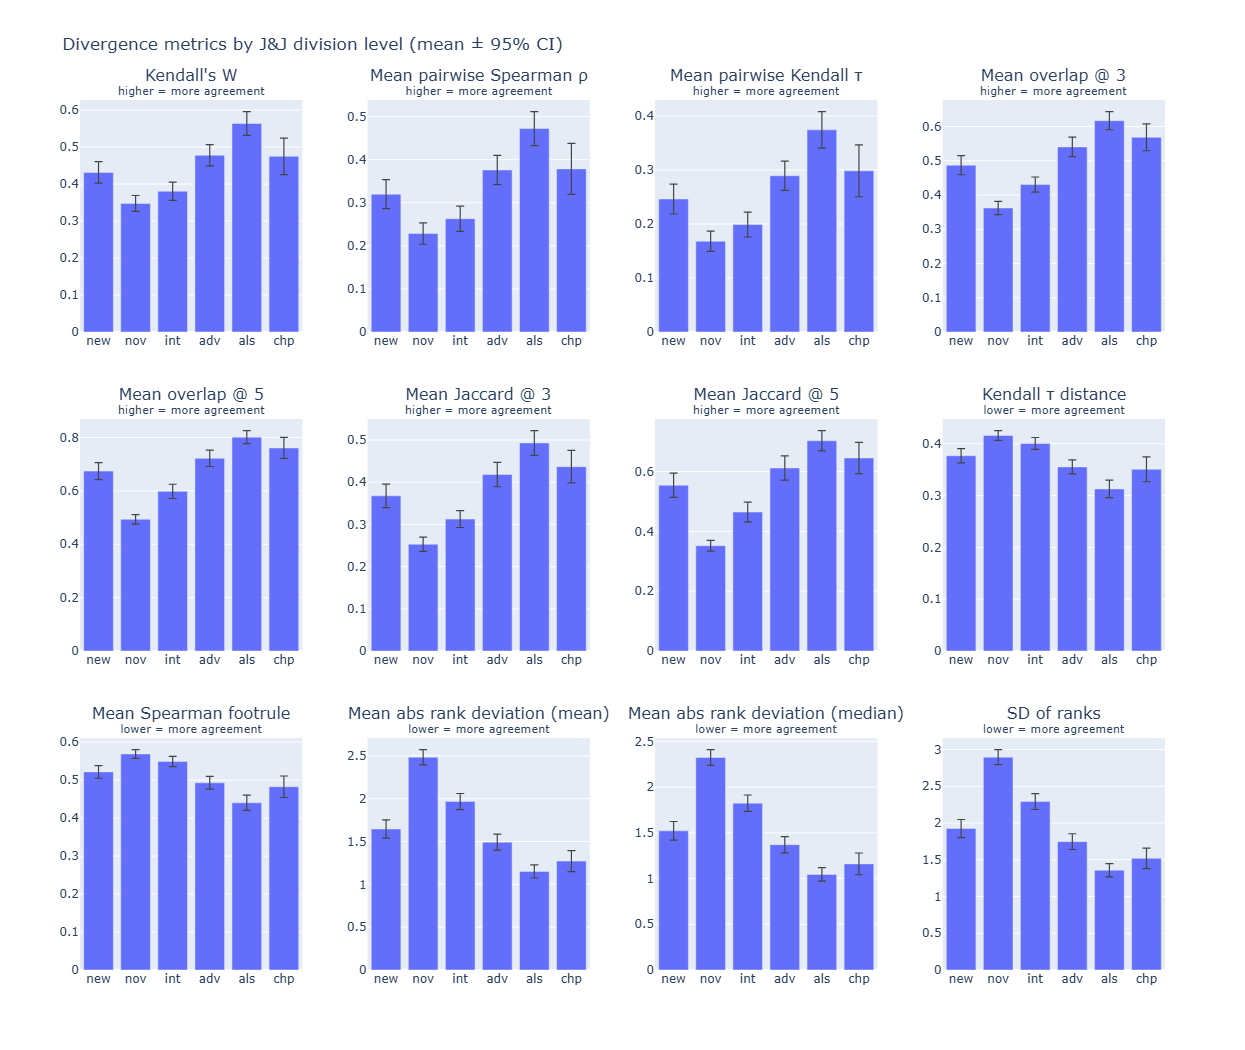

In [4]:
NCOLS = 4
NROWS = (len(METRICS) + NCOLS - 1) // NCOLS  # 3

subplot_titles = [f"{title}<br><sup>{note}</sup>" for _, title, note in METRICS]
subplot_titles += [""] * (NROWS * NCOLS - len(METRICS))

fig = make_subplots(
    rows=NROWS, cols=NCOLS,
    subplot_titles=subplot_titles,
    vertical_spacing=0.10,
    horizontal_spacing=0.06,
)

BAR_COLOR = "#636EFA"

for i, (col, title, note) in enumerate(METRICS):
    row, col_num = divmod(i, NCOLS)
    row, col_num = row + 1, col_num + 1

    fig.add_trace(
        go.Bar(
            x=agg_mean["level"],
            y=agg_mean[col],
            showlegend=False,
            marker_color=BAR_COLOR,
            error_y=dict(
                type="data",
                array=agg_ci[col],
                visible=True,
                thickness=1.2,
                color="#444",
            ),
        ),
        row=row, col=col_num,
    )

fig.update_layout(
    height=NROWS * 350,
    title="Divergence metrics by J&J division level (mean ± 95% CI)",
)
fig.show()

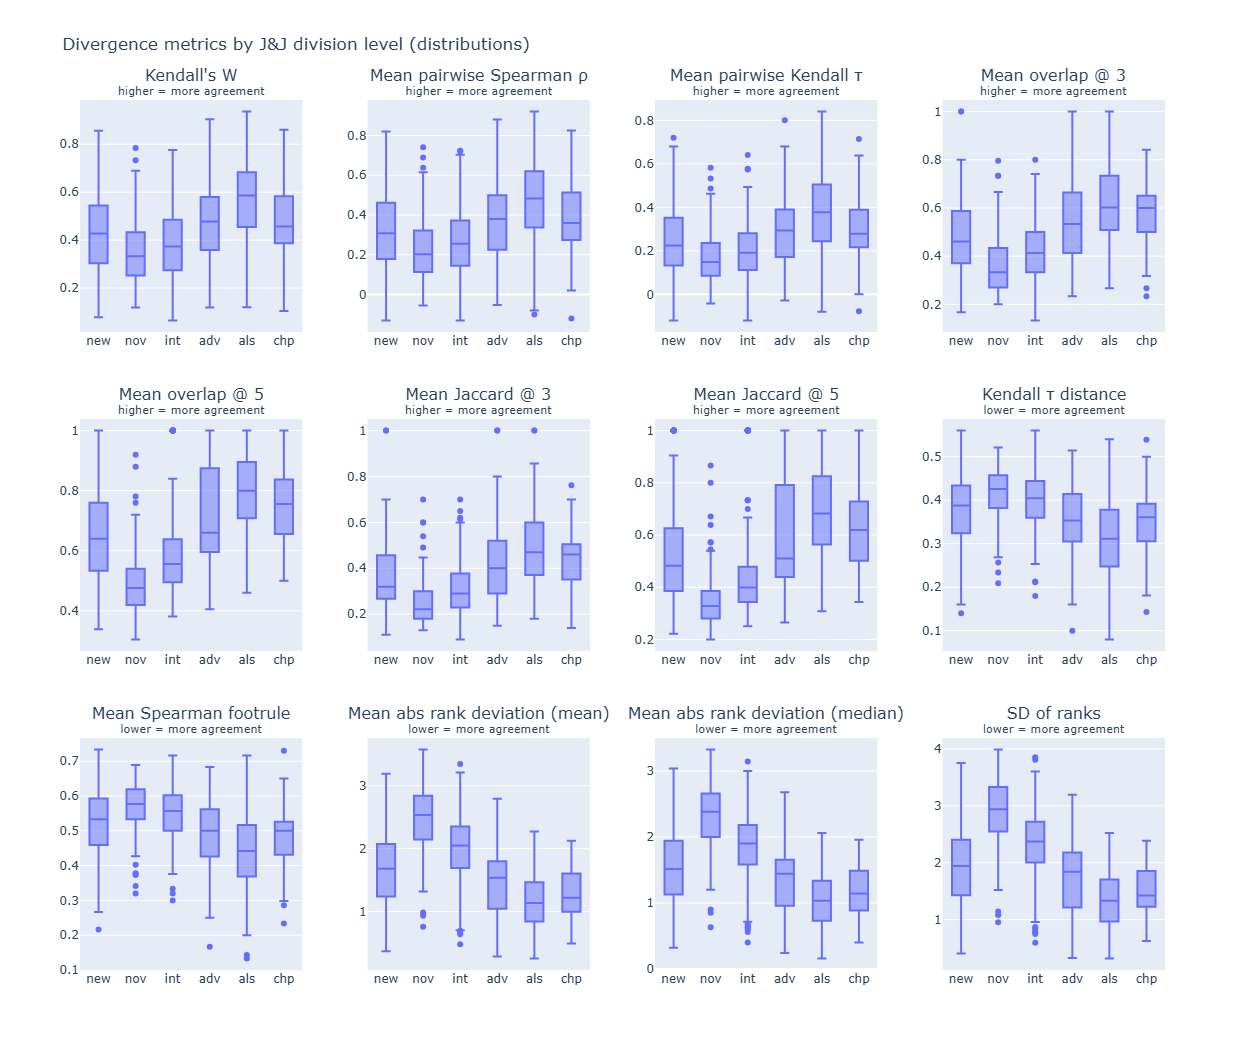

In [5]:
fig2 = make_subplots(
    rows=NROWS, cols=NCOLS,
    subplot_titles=subplot_titles,
    vertical_spacing=0.10,
    horizontal_spacing=0.06,
)

for i, (col, title, note) in enumerate(METRICS):
    row, col_num = divmod(i, NCOLS)
    row, col_num = row + 1, col_num + 1
    fig2.add_trace(
        go.Box(
            x=df["level"],
            y=df[col],
            name=col,
            showlegend=False,
            marker_color=BAR_COLOR,
        ),
        row=row, col=col_num,
    )

fig2.update_layout(
    height=NROWS * 350,
    title="Divergence metrics by J&J division level (distributions)",
)
fig2.update_xaxes(categoryorder="array", categoryarray=LEVEL_ORDER)
fig2.show()